
# ** Unsupervised Learning – Clustering or Anomaly Detection**

**Due:** July 28 (Monday) | **Total Points:** 100  
**Submission:** Share a link to your completed Google Colab notebook (set sharing to *“University of Colorado Boulder”*)



## 🎯 What You’ll Learn
- Implement unsupervised learning pipelines using real-world data  
- Choose and apply appropriate clustering or anomaly detection algorithms  
- Visualize and interpret learned structure (e.g. clusters, outliers)  
- Evaluate your model using domain knowledge or internal metrics  
- Reflect on modeling tradeoffs and your reasoning process  



## ⚙️ Project Structure

Pick **one** of the two unsupervised tasks below:

1. **Clustering Task** – Group similar items together  
2. **Anomaly Detection Task** – Identify rare or unusual points  

You’ll:
- Perform EDA to understand the data structure  
- Build preprocessing + modeling pipelines  
- Visualize and evaluate your results  
- Reflect on what your model learned  



## 📂 Dataset Choices (Pick One Dataset Only)

You may choose any dataset that suits either task. For example:

- **Clustering:** customer data, songs, books, animals, etc.  
- **Anomaly Detection:** fraud detection, server logs, product quality, etc.  

> # *You may not use any datasets we covered in class*


# 🧠 You May Use AI, But...

AI tools like ChatGPT can be helpful, but they are not a substitute for your thinking.

**You may use AI to:**

- Ask for help writing functions
- Look up syntax
- Get suggestions on model types


**You must NOT:**

- Submit copy-pasted code without understanding it
- Skip explanation and reflection questions


## 🔄 Workflow (For Your Chosen Task)

### Part 1 – EDA + Task Definition (5 pts)

- Load and inspect the dataset  
- Explore data distributions and feature types  
- Write:  
    - What is the structure of the data?  
    - What problem are you trying to solve? Why did you choose this task (clustering or anomaly detection)?


In [1]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

In [ ]:
# Load in Data [https://www.kaggle.com/datasets/agungpambudi/network-malware-detection-connection-analysis]

file_path = '/content/drive/MyDrive/info_4604/datasets/CTU-IoT-Malware-Capture-34-1conn.log.labeled.csv'
import pandas as pd
import numpy as np
df = pd.read_csv(file_path, sep='|')
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label
0,1.545404e+09,CrDn63WjJEmrWGjqf,192.168.1.195,41040,185.244.25.235,80,tcp,-,3.139211,0,...,-,0,S,3,180,0,0,-,Benign,-
1,1.545404e+09,CY9lJW3gh1Eje4usP6,192.168.1.195,41040,185.244.25.235,80,tcp,-,-,-,...,-,0,S,1,60,0,0,-,Benign,-
2,1.545404e+09,CcFXLynukEDnUlvgl,192.168.1.195,41040,185.244.25.235,80,tcp,-,-,-,...,-,0,S,1,60,0,0,-,Benign,-
3,1.545404e+09,CDrkrSobGYxHhYfth,192.168.1.195,41040,185.244.25.235,80,tcp,http,1.477656,149,...,-,2896,ShADadttcfF,94,5525,96,139044,-,Benign,-
4,1.545404e+09,CTWZQf2oJSvq6zmPAc,192.168.1.195,41042,185.244.25.235,80,tcp,-,3.147116,0,...,-,0,S,3,180,0,0,-,Benign,-


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23145 entries, 0 to 23144
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ts              23145 non-null  float64
 1   uid             23145 non-null  object 
 2   id.orig_h       23145 non-null  object 
 3   id.orig_p       23145 non-null  int64  
 4   id.resp_h       23145 non-null  object 
 5   id.resp_p       23145 non-null  int64  
 6   proto           23145 non-null  object 
 7   service         23145 non-null  object 
 8   duration        23145 non-null  object 
 9   orig_bytes      23145 non-null  object 
 10  resp_bytes      23145 non-null  object 
 11  conn_state      23145 non-null  object 
 12  local_orig      23145 non-null  object 
 13  local_resp      23145 non-null  object 
 14  missed_bytes    23145 non-null  int64  
 15  history         23145 non-null  object 
 16  orig_pkts       23145 non-null  int64  
 17  orig_ip_bytes   23145 non-null 

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ts,23145.0,NaN,NaN,NaN,1545456754.085251,22718.133466,1545403816.8709,1545461182.458462,1545466969.42629,1545466981.859938,1545490213.942227
uid,23145,23145,Ct2Yhy4d33oL3yyZY9,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id.orig_h,23145,2,192.168.1.195,23144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id.orig_p,23145.0,NaN,NaN,NaN,56409.651847,17176.590987,0.0,53622.0,65279.0,65279.0,65279.0
id.resp_h,23145,49,123.59.209.185,14260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id.resp_p,23145.0,NaN,NaN,NaN,2324.573558,5362.933817,1.0,80.0,80.0,6667.0,63798.0
proto,23145,2,tcp,21331,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service,23145,5,-,21298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,23145,4654,-,17824,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orig_bytes,23145,29,-,17824,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Part 1 Task Definition
  - What is the structure of the data?

  The structure of this data is 23 columns and 23145 entries with objects, floats, and int

  - What problem are you trying to solve? Why did you choose this task (clustering or anomaly detection)?

  I want to use Label as target try to use some features that I engineered from the raw columns to create a spam filter


### Part 2 – Preprocessing + Pipeline (10 pts)

- Identify and handle missing values  
- Identify categorical vs numeric features  
- Build preprocessing steps as needed (`SimpleImputer`, `OneHotEncoder`, `StandardScaler`, etc.)  
- Wrap everything into a `Pipeline`  

Explain in Markdown:  
- Why did you choose each step?  
- Did you make any assumptions about the features?


In [ ]:
## Identify and Handle Missing Values

'''
For handling missing values, we can see that the column for detailed-label is
empty or '-', so we can drop that, and we want our target to be the label column.
For predicting 'Malicious' activity. It also turns out that with this data set,
this sheet for the dataset, they combined 'label' and 'detailed-label', so we
may be able to predict more.
'''
# Replace missing values with NaN and convert columns with string numbers to floats
df.replace('-', np.nan, inplace=True)
for col in ['duration', 'orig_bytes', 'resp_bytes', 'orig_pkts', 'resp_pkts', 'orig_ip_bytes', 'resp_ip_bytes']:
    df[col] = df[col].astype(float)

# Convert timestamp to datetime for feature engineering
df['ts'] = pd.to_datetime(df['ts'], unit='s')
df = df.sort_values(['id.orig_h', 'ts'])

/tmp/ipython-input-5-1133673069.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace('-', np.nan, inplace=True)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


## Feature Engineering

# IP addresses are categories and not int
df["id.orig_p"] = df["id.orig_p"].astype("category")
df["id.resp_p"] = df["id.resp_p"].astype("category")

# Rolling count of connections from the same source IP in last 10 seconds
df = df.set_index('ts').sort_index()
df['connections_last_10s'] = (
    df
    .groupby('id.orig_h')['uid']
    .rolling('10s')
    .count()
    .reset_index(level=0, drop=True)
)

# Number of unique destinations per uid
df['n_dest_ips'] = df.groupby('uid')['id.resp_h'].transform('nunique')


# Byte ratios
df['byte_ratio'] = df['orig_bytes'] / (df['resp_bytes'] + 1)
df['pkt_ratio'] = df['orig_pkts'] / (df['resp_pkts'] + 1)

# Total bytes
df['total_bytes'] = df['orig_bytes'] + df['resp_bytes']
df['total_pkts'] = df['orig_pkts'] + df['resp_pkts']
df['total_ip_bytes'] = df['orig_ip_bytes'] + df['resp_ip_bytes']

# Is repeated uid
df['uid_repeated'] = df.duplicated('uid', keep=False).astype(int)

# Convert categorical variable into dummy/indicator variables
df = pd.get_dummies(df, columns=["id.orig_p","id.resp_p"], prefix=["src_p","dst_p"])

# Drop raw identifiers and redundant columns
df_feat = df.drop(columns=[
    'uid', 'id.orig_h',
    'id.resp_h',
    'detailed-label', 'tunnel_parents',
    'orig_bytes', 'resp_bytes',
    'orig_pkts', 'resp_pkts',
    'orig_ip_bytes', 'resp_ip_bytes',
    'local_orig', 'local_resp',
    ])

X = df_feat.drop(columns=['label'])
y_true = df_feat['label']

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

## Identify Categorical and Numeric Features

numeric_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Calculate correlation matrix
# corr = X[numeric_cols].corr()
# sns.heatmap(corr, annot=True, fmt=".2f")
# plt.show()

In [ ]:
## Build preprocessing

# Scale for Numerical

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='mean', keep_empty_features=True)),
    ('scaler', StandardScaler())
])

# OneHotEncoding for Categorical

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
    ('encoder', OneHotEncoder())
])

preprocess = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)
])

preprocess.fit(X)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(keep_empty_features=True)),
                                                 ('scaler', StandardScaler())]),
                                 ['duration', 'missed_bytes',
                                  'connections_last_10s', 'n_dest_ips',
                                  'byte_ratio', 'pkt_ratio', 'total_bytes',
                                  'total_pkts', 'total_ip_bytes',
                                  'uid_repeated']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(keep_empty_features=True,
                                                                strategy='most_frequent')),
                                                 ('encoder', OneHotEncoder())]),
                                 ['proto', 'service', 'conn_state',
                                  'history'])])

In [ ]:
print(len(df_feat))
print(sum(df_feat['label'] == 'Benign'))
len(df_feat) - sum(df_feat['label'] == 'Benign')
sum(df_feat['label'] == 'Benign') / len(df_feat)

23145
1923


0.0830848995463383

In [ ]:
## Wrap into pipeline
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest

pipeline = Pipeline([
    ('preprocess', preprocess),
    ('clf', IsolationForest(
        contamination=0.01,
        random_state=42,
        n_jobs=-1
        ))
])

pipeline.fit(X)

scores = pipeline.decision_function(X)
y_pred = pipeline.predict(X)

df_feat['is_anomaly'] = (y_pred == -1).astype(int)

def assign_mal_type(row):
    if row['is_anomaly'] == 0:
        return 'Benign'
    # DDoS: very high volume in short time
    if row['connections_last_10s'] > 100 and row['total_bytes'] > 1e6:
        return 'Malicious DDoS'
    # C&C: long-lived + low byte ratio + low jitter
    if row['duration'] > 300 and row.get('delta_jitter', np.inf) < 1:
        return 'Malicious C&C'
    # Otherwise, treat as port scan
    return 'Malicious PartOfAHorizontalPortScan'


df_feat['label_type_pred'] = df_feat.apply(assign_mal_type, axis=1)

# [df_feat['label_type_pred'].value_counts(), df['label'].value_counts()]
# mask = (df_feat['total_bytes'] > 1e6)
# count = mask.sum()
# print(f"{count} rows meet the criteria")

# eyeglass = df_feat[['is_anomaly','label_type_pred', 'label']]
# eyeglass.head()
# df_feat['connections_last_10s'].value_counts()

from sklearn.metrics import classification_report

print(classification_report(
    df_feat['label'],
    df_feat['label_type_pred'],
    labels=['Benign','DDoS','C&C','PortScan'],
    zero_division=0
))

              precision    recall  f1-score   support

      Benign       0.07      0.89      0.14      1923
        DDoS       0.00      0.00      0.00         0
         C&C       0.00      0.00      0.00         0
    PortScan       0.00      0.00      0.00         0

   micro avg       0.07      0.89      0.14      1923
   macro avg       0.02      0.22      0.03      1923
weighted avg       0.07      0.89      0.14      1923




### Part 3 – Model Training + Evaluation (20 pts)

- Choose **one** algorithm:
    - Clustering: `KMeans`, `DBSCAN`, or `AgglomerativeClustering`  
    - Anomaly Detection: `IsolationForest`, `OneClassSVM`, or `LocalOutlierFactor`  
- Train your model and generate cluster or anomaly labels  
- Evaluate using:
    - Clustering: `silhouette_score`, domain insights  
    - Anomaly: confusion matrix (if ground truth), outlier rates  

Explain in Markdown:  
- How do you know your model is working well?  
- Are the results sensible given your EDA?


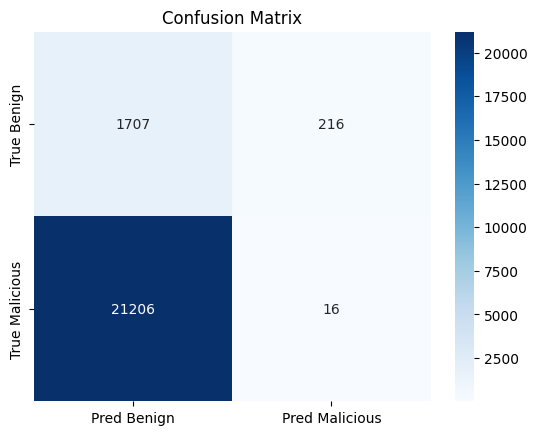

              precision    recall  f1-score   support

      Benign       0.07      0.89      0.14      1923
   Malicious       0.07      0.00      0.00     21222

    accuracy                           0.07     23145
   macro avg       0.07      0.44      0.07     23145
weighted avg       0.07      0.07      0.01     23145



In [ ]:
y_true_bin = df_feat['label'].apply(lambda s: 0 if s=='Benign' else 1)
y_pred_bin = df_feat['is_anomaly']

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_bin, y_pred_bin)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Benign','Pred Malicious'],
            yticklabels=['True Benign','True Malicious'])
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_true_bin,
    y_pred_bin,
    target_names=['Benign','Malicious']
))


### Part 4 – Visualization + Insights (15 pts)

- Use dimensionality reduction (e.g. PCA, t-SNE) to visualize the structure  
- Visualize clusters or anomalies using `scatterplot`, `pairplot`, etc.  
- Interpret:
    - What patterns or groups do you see?  
    - What do your visualizations reveal about the data?


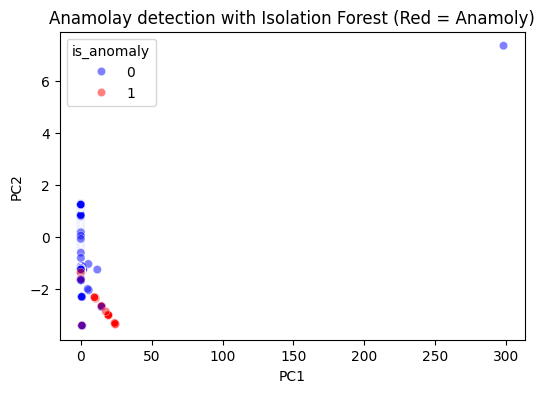

In [ ]:
from sklearn.manifold import TSNE

X_pre = preprocess.transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_pre)

# plt.figure()
# plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_feat['is_anomaly'])
# plt.title("PCA: First Two Principal Components")
# plt.xlabel("PC1")
# plt.ylabel("PC2")
# plt.legend()
# plt.show()


plt.figure(figsize=(6,4))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=y_pred_bin,
    palette={0:'blue', 1:'red'},
    alpha=0.5
)
plt.title('Anamolay detection with Isolation Forest (Red = Anamoly)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

I am noticing what looks like a cluster of anomalies that lies on a line in red and I am curious what that could be or if it can be isolated to see what correlation there is.


### Part 5 – Reflection + AI Disclosure (10 pts – 100-150 words)

In Markdown, answer:

1. **Why did you choose clustering or anomaly detection?**  
2. **What was the hardest part of this workflow?**  
3. **How did your modeling choices affect the results?**  
4. **If you used AI tools (e.g. ChatGPT):**
    - What did you ask?
    - How did you validate the answers?


1. I chose Anomaly Detection, which made the questions a little confusing because they correlated more closely with the clustering methods we used in class to get to the end product. I also chose Anomaly because I was using a network log as a datasheet.

2. The hardest part of this workflow was reorganizing the data to be useful for the model at all, because there are general indicators of malicious activity, but the indicators are derived from feature engineering the raw columns and also reducing the redundancy in the Data.

3. I saw that there are other features or indicators taht would more closely be indicative of malicious activity at the end as my model was not very accurate.

4. I used ChatGPT to help create ideas for feature engineering that would help increase the score and debugging. I asked things like helping me determine which features for the correlation graph would best be used in my pipeline and it help me understand the graph itself. I would cross reference by checking its sources and checking other sources.